<center><h1>Satish_Manvika_HW7</h1></center>

Name: Manvika Satish
<br>
Github Username: manvsatish
<br>
USC ID: 5582061880

## 1. Multi-class and Multi-Label Classification Using Support Vector Machines

Import packages

In [1]:
import warnings
warnings.filterwarnings("ignore")
from pathlib import Path
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC, LinearSVC
from sklearn.cluster import KMeans
from sklearn.metrics import (accuracy_score, hamming_loss, silhouette_score)
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

RANDOM_STATE = 552
pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")
print("Packages imported successfully.")

Packages imported successfully.


### (a) Download the Anuran Calls (MFCCs) Data Set

In [2]:
possible_paths = [Path("../data/Frogs_MFCCs.csv"), Path("data/Frogs_MFCCs.csv"),] #locate & load dataset
data_path = next((path for path in possible_paths if path.exists()), None)

if data_path is None:
    raise FileNotFoundError("Frogs_MFCCs.csv was not found in the data folder.")

frogs = pd.read_csv(data_path)
print(f"Dataset path: {data_path}")
print(f"Dataset shape: {frogs.shape}")
print(f"Number of missing values: {frogs.isna().sum().sum()}")
display(frogs.head())
print("\nColumn names:")
print(frogs.columns.tolist())

feature_columns = [column for column in frogs.columns if column.startswith("MFCCs_")] #separate 22 predictors, 3 labels, and id
label_columns = ["Family", "Genus", "Species"]
X = frogs[feature_columns]
y = frogs[label_columns]

label_combinations = y.astype(str).agg("_".join, axis=1) # combined label triplet to keep class distributions

#random selecttion 70% for training and 30% for testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=RANDOM_STATE, stratify=label_combinations)
print(f"Number of predictors: {X.shape[1]}")
print(f"Label columns: {label_columns}")
print(f"X training shape: {X_train.shape}")
print(f"X testing shape: {X_test.shape}")
print(f"y training shape: {y_train.shape}")
print(f"y testing shape: {y_test.shape}")
print(f"Training percentage: {100 * len(X_train) / len(X):.1f}%")
print(f"Testing percentage: {100 * len(X_test) / len(X):.1f}%")
print(f"Random seed: {RANDOM_STATE}")

Dataset path: ../data/Frogs_MFCCs.csv
Dataset shape: (7195, 26)
Number of missing values: 0


,MFCCs_ 1,MFCCs_ 2,MFCCs_ 3,MFCCs_ 4,MFCCs_ 5,MFCCs_ 6,MFCCs_ 7,MFCCs_ 8,MFCCs_ 9,MFCCs_10,MFCCs_11,MFCCs_12,MFCCs_13,MFCCs_14,MFCCs_15,MFCCs_16,MFCCs_17,MFCCs_18,MFCCs_19,MFCCs_20,MFCCs_21,MFCCs_22,Family,Genus,Species,RecordID
0,1.0,0.152936,-0.105586,0.200722,0.317201,0.260764,0.100945,-0.150063,-0.171128,0.124676,0.188654,-0.075622,-0.156436,0.082245,0.135752,-0.024017,-0.108351,-0.077623,-0.009568,0.057684,0.118680,0.014038,Leptodactylidae,Adenomera,AdenomeraAndre,1
1,1.0,0.171534,-0.098975,0.268425,0.338672,0.268353,0.060835,-0.222475,-0.207693,0.170883,0.270958,-0.095004,-0.254341,0.022786,0.163320,0.012022,-0.090974,-0.056510,-0.035303,0.020140,0.082263,0.029056,Leptodactylidae,Adenomera,AdenomeraAndre,1
2,1.0,0.152317,-0.082973,0.287128,0.276014,0.189867,0.008714,-0.242234,-0.219153,0.232538,0.266064,-0.072827,-0.237384,0.050791,0.207338,0.083536,-0.050691,-0.023590,-0.066722,-0.025083,0.099108,0.077162,Leptodactylidae,Adenomera,AdenomeraAndre,1
3,1.0,0.224392,0.118985,0.329432,0.372088,0.361005,0.015501,-0.194347,-0.098181,0.270375,0.267279,-0.162258,-0.317084,-0.011567,0.100413,-0.050224,-0.136009,-0.177037,-0.130498,-0.054766,-0.018691,0.023954,Leptodactylidae,Adenomera,AdenomeraAndre,1
4,1.0,0.087817,-0.068345,0.306967,0.330923,0.249144,0.006884,-0.265423,-0.172700,0.266434,0.332695,-0.100749,-0.298524,0.037439,0.219153,0.062837,-0.048885,-0.053074,-0.088550,-0.031346,0.108610,0.079244,Leptodactylidae,Adenomera,AdenomeraAndre,1



Column names:
['MFCCs_ 1', 'MFCCs_ 2', 'MFCCs_ 3', 'MFCCs_ 4', 'MFCCs_ 5', 'MFCCs_ 6', 'MFCCs_ 7', 'MFCCs_ 8', 'MFCCs_ 9', 'MFCCs_10', 'MFCCs_11', 'MFCCs_12', 'MFCCs_13', 'MFCCs_14', 'MFCCs_15', 'MFCCs_16', 'MFCCs_17', 'MFCCs_18', 'MFCCs_19', 'MFCCs_20', 'MFCCs_21', 'MFCCs_22', 'Family', 'Genus', 'Species', 'RecordID']
Number of predictors: 22
Label columns: ['Family', 'Genus', 'Species']
X training shape: (5036, 22)
X testing shape: (2159, 22)
y training shape: (5036, 3)
y testing shape: (2159, 3)
Training percentage: 70.0%
Testing percentage: 30.0%
Random seed: 552


### (b) Train a classifier for each label

#### (i) Research

### Exact Match, Hamming Score, and Hamming Loss
Each observation has three labels: family, genus, and species. Therefore, model performance should be evaluated both at the complete label-set level and at the individual-label level.

#### Exact Match
Exact match, also known as subset accuracy, is the proportion of observations for which **all three predicted labels** exactly match their corresponding true labels.
$$
\text{Exact Match}
=
\frac{1}{n}
\sum_{i=1}^{n}
I\left(\hat{\mathbf{y}}_i=\mathbf{y}_i\right)
$$
A prediction receives credit only if its family, genus, and species are all correct. Exact match ranges from 0 to 1, and a larger value is better.

#### Hamming Loss
Hamming loss is the proportion of individual labels that are predicted incorrectly.
$$
\text{Hamming Loss}
=
\frac{1}{nL}
\sum_{i=1}^{n}
\sum_{j=1}^{L}
I\left(\hat{y}_{ij}\neq y_{ij}\right)
$$
Here, \(n\) is the number of observations and \(L=3\) is the number of labels. Hamming loss ranges from 0 to 1, and a smaller value is better.

#### Hamming Score
Hamming score is the proportion of individual labels that are predicted correctly. With a fixed number of labels for every observation, it is the complement of Hamming loss.
$$
\text{Hamming Score}
=
\frac{1}{nL}
\sum_{i=1}^{n}
\sum_{j=1}^{L}
I\left(\hat{y}_{ij}=y_{ij}\right)
=
1-\text{Hamming Loss}
$$
Hamming score ranges from 0 to 1, and a larger value is better. 

Exact match is stricter than Hamming score because exact match requires all three labels to be correct simultaneously, whereas Hamming score gives partial credit when only some labels are correct.

In [3]:
#calculate exact match, hamming score, and hamming loss.
def multilabel_metrics(y_true, y_pred):
    y_true_array = np.asarray(y_true)
    y_pred_array = np.asarray(y_pred)

    if y_true_array.shape != y_pred_array.shape:
        raise ValueError("y_true and y_pred must have the same shape.")

    exact_match = np.mean(np.all(y_true_array == y_pred_array, axis=1))
    hamming_loss_value = np.mean(y_true_array != y_pred_array)
    hamming_score = 1.0 - hamming_loss_value
    return {"Exact Match": exact_match, "Hamming Score": hamming_score, "Hamming Loss": hamming_loss_value}

# verify metric function with example
example_true = np.array([["Family_A", "Genus_A", "Species_A"], ["Family_B", "Genus_B", "Species_B"]])
example_pred = np.array([["Family_A", "Genus_A", "Species_A"], ["Family_B", "Genus_B", "Species_A"]])
example_results = multilabel_metrics(example_true, example_pred)
print("Metric-function verification:")
for metric, value in example_results.items():
    print(f"{metric}: {value:.4f}")

Metric-function verification:
Exact Match: 0.5000
Hamming Score: 0.8333
Hamming Loss: 0.1667


#### (ii) Train a SVM for each of the labels

In [4]:
from sklearn.multiclass import OneVsRestClassifier

In [5]:
# gaussian-kernel svms with one v all classification
# C - SVM penalty, gamma - gussian-kernel width

parameter_grid = {"classifier__estimator__C": [0.1, 1, 10, 100, 1000], "classifier__estimator__gamma": [0.01, 0.1, 1, 10]}
cv_strategy = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)
rbf_models = {}
rbf_predictions = pd.DataFrame(index=y_test.index)
rbf_results = []

for label in label_columns:
    print(f"Training Gaussian SVM for {label}...")
    pipeline = Pipeline([("scaler", StandardScaler()), ("classifier", OneVsRestClassifier(SVC(kernel="rbf"), n_jobs=1,))])

    grid_search = GridSearchCV(estimator=pipeline, param_grid=parameter_grid, scoring="accuracy", cv=cv_strategy, n_jobs=-1, refit=True)
    grid_search.fit(X_train, y_train[label])
    predictions = grid_search.predict(X_test)
    rbf_models[label] = grid_search.best_estimator_
    rbf_predictions[label] = predictions
    rbf_results.append({"Label": label, "Best C": grid_search.best_params_["classifier__estimator__C"], "Best Gamma": grid_search.best_params_["classifier__estimator__gamma"], "Best Mean CV Accuracy": grid_search.best_score_, "Test Accuracy": accuracy_score(y_test[label], predictions)})

rbf_results = pd.DataFrame(rbf_results)
rbf_metric_results = multilabel_metrics(y_test[label_columns], rbf_predictions[label_columns])

print("\nGaussian SVM cross-validation and test results:")
display(rbf_results.style.format({"Best C": "{:.4f}", "Best Gamma": "{:.4f}", "Best Mean CV Accuracy": "{:.4f}", "Test Accuracy": "{:.4f}"}))
print("\nOverall multi-label test performance:")
for metric, value in rbf_metric_results.items():
    print(f"{metric}: {value:.4f}")

Training Gaussian SVM for Family...
Training Gaussian SVM for Genus...
Training Gaussian SVM for Species...

Gaussian SVM cross-validation and test results:


,Label,Best C,Best Gamma,Best Mean CV Accuracy,Test Accuracy
0,Family,10.0000,0.1000,0.9907,0.9907
1,Genus,1000.0000,0.0100,0.9887,0.9889
2,Species,100.0000,0.1000,0.9869,0.9907



Overall multi-label test performance:
Exact Match: 0.9819
Hamming Score: 0.9901
Hamming Loss: 0.0099


#### Gaussian SVM Results and Conclusion
The predictors were standardized and separate Gaussian-kernel SVMs were trained for the family, genus, and species labels using the one vs all approach. Ten-fold stratified cross-validation selected \(C\) and \(\gamma\) independently for each label.

The selected parameters were family, genus, and species:
- Family: \(C=10\), \(\gamma=0.1\)
- Genus: \(C=1000\), \(\gamma=0.01\)
- Species: \(C=100\), \(\gamma=0.1\)

All three classifiers received test accuracies of ~ 99%. The combined model achieved an exact-match score of 0.9819, meaning that all three labels were predicted correctly for approximately 98.19% of the test observations. Its Hamming score was 0.9901, while its Hamming loss was 0.0099. So, only approximately 0.99% of the individual family, genus, and species labels were classified incorrectly. Overall, the Gaussian one vs all SVMs performed very well on this multi-class, multi-label classification problem.

#### (iii) Repeat 1(b)ii with L1-penalized SVMs

In [6]:
l1_parameter_grid = {"classifier__estimator__C": [0.001, 0.01, 0.1, 1, 10, 100]} #l1-penalized linear svms w/ standardized predictors
l1_models = {}
l1_predictions = pd.DataFrame(index=y_test.index)
l1_results = []

for label in label_columns:
    print(f"Training L1-penalized SVM for {label}...")
    pipeline = Pipeline([("scaler", StandardScaler()), ("classifier", OneVsRestClassifier(LinearSVC(penalty="l1", dual=False, max_iter=50000, random_state=RANDOM_STATE), n_jobs=1))])
    grid_search = GridSearchCV(estimator=pipeline, param_grid=l1_parameter_grid, scoring="accuracy", cv=cv_strategy, n_jobs=-1, refit=True)
    grid_search.fit(X_train, y_train[label])
    predictions = grid_search.predict(X_test)
    l1_models[label] = grid_search.best_estimator_
    l1_predictions[label] = predictions
    fitted_classifier = grid_search.best_estimator_.named_steps["classifier"]
    nonzero_coefficients = sum(np.count_nonzero(estimator.coef_) for estimator in fitted_classifier.estimators_)
    total_coefficients = sum(estimator.coef_.size for estimator in fitted_classifier.estimators_)

    l1_results.append({"Label": label, "Best C": grid_search.best_params_["classifier__estimator__C"], "Best Mean CV Accuracy": grid_search.best_score_, "Test Accuracy": accuracy_score(y_test[label], predictions), "Nonzero Coefficients": nonzero_coefficients, "Total Coefficients": total_coefficients})

l1_results = pd.DataFrame(l1_results)
l1_metric_results = multilabel_metrics(y_test[label_columns], l1_predictions[label_columns])

print("\nL1-penalized SVM cross-validation and test results:")
display(l1_results.style.format({"Best C": "{:.4f}", "Best Mean CV Accuracy": "{:.4f}", "Test Accuracy": "{:.4f}"}))
print("\nOverall multi-label test performance:")
for metric, value in l1_metric_results.items():
    print(f"{metric}: {value:.4f}")

Training L1-penalized SVM for Family...
Training L1-penalized SVM for Genus...
Training L1-penalized SVM for Species...

L1-penalized SVM cross-validation and test results:


,Label,Best C,Best Mean CV Accuracy,Test Accuracy,Nonzero Coefficients,Total Coefficients
0,Family,10.0000,0.9341,0.9421,88,88
1,Genus,100.0000,0.9474,0.9532,176,176
2,Species,10.0000,0.9567,0.9588,220,220



Overall multi-label test performance:
Exact Match: 0.9157
Hamming Score: 0.9514
Hamming Loss: 0.0486


#### L1-Penalized SVM Results and Conclusion
The predictors were standardized before fitting separate L1-penalized linear SVMs for the family, genus, and species labels. Each classifier used the one vs all approach, and the penalty parameter \(C\) was selected using ten-fold stratified cross-validation.

The selected penalty parameters were family, genus, and species (like before):
- Family: \(C=10\)
- Genus: \(C=100\)
- Species: \(C=10\)

The family, genus, and species classifiers achieved test accuracies of 0.9421, 0.9532, and 0.9588, respectively. The combined classifier got an exact-match score of 0.9157, a Hamming score of 0.9514, and a Hamming loss of 0.0486. All fitted coefficients stayed nonzero. The relatively large selected values of \(C\) correspond to weak L1 regularization, showing that stronger sparsity brought down cross-validation accuracy for this dataset. The L1-penalized linear SVM performed worse than the Gaussian SVM, whose exact-match score was 0.9819 and Hamming loss was 0.0099. This shows that nonlinear class boundaries are useful for distinguishing the frog labels.

#### (iv) Repeat 1(b)iii by using SMOTE or any other method for imbalance

In [7]:
#summary of original class imbalance for each label
imbalance_summary = []
for label in label_columns:
    class_counts = y_train[label].value_counts()
    imbalance_summary.append({"Label": label, "Number of Classes": class_counts.size, "Minority Class Count": class_counts.min(), "Majority Class Count": class_counts.max(), "Majority-to-Minority Ratio": (class_counts.max() / class_counts.min())})

imbalance_summary = pd.DataFrame(imbalance_summary)
print("Training-set class imbalance:")
display(imbalance_summary.style.format({"Majority-to-Minority Ratio": "{:.2f}"}))

# l1-penalized linear svms with smote inside cross valid
smote_l1_models = {}
smote_l1_predictions = pd.DataFrame(index=y_test.index)
smote_l1_results = []

for label in label_columns:
    print(f"Training SMOTE L1-SVM for {label}...")
    pipeline = ImbPipeline([("scaler", StandardScaler()), ("smote", SMOTE(random_state=RANDOM_STATE)), ("classifier", OneVsRestClassifier(LinearSVC(penalty="l1", dual=False, max_iter=50000, random_state=RANDOM_STATE), n_jobs=1))])
    grid_search = GridSearchCV(estimator=pipeline, param_grid=l1_parameter_grid, scoring="accuracy", cv=cv_strategy, n_jobs=-1, refit=True)
    grid_search.fit(X_train, y_train[label])
    predictions = grid_search.predict(X_test)
    smote_l1_models[label] = grid_search.best_estimator_
    smote_l1_predictions[label] = predictions
    smote_l1_results.append({"Label": label, "Best C": grid_search.best_params_["classifier__estimator__C"], "Best Mean CV Accuracy": grid_search.best_score_, "Test Accuracy": accuracy_score(y_test[label], predictions)})

smote_l1_results = pd.DataFrame(smote_l1_results)
smote_l1_metric_results = multilabel_metrics(y_test[label_columns], smote_l1_predictions[label_columns])

print("\nSMOTE L1-SVM cross-validation and test results:")
display(smote_l1_results.style.format({"Best C": "{:.4f}", "Best Mean CV Accuracy": "{:.4f}", "Test Accuracy": "{:.4f}"}))
print("\nOverall SMOTE multi-label test performance:")
for metric, value in smote_l1_metric_results.items():
    print(f"{metric}: {value:.4f}")

# compare the three multi classification approac
classification_comparison = pd.DataFrame([
    {"Model": "Gaussian SVM", **rbf_metric_results},
    {"Model": "L1-Penalized SVM", **l1_metric_results},
    {"Model": "SMOTE L1-SVM", **smote_l1_metric_results}
])

print("\nOverall classifier comparison:")
display(classification_comparison.style.format({"Exact Match": "{:.4f}", "Hamming Score": "{:.4f}", "Hamming Loss": "{:.4f}"}))

Training-set class imbalance:


,Label,Number of Classes,Minority Class Count,Majority Class Count,Majority-to-Minority Ratio
0,Family,4,48,3093,64.44
1,Genus,8,48,2904,60.50
2,Species,10,48,2434,50.71


Training SMOTE L1-SVM for Family...
Training SMOTE L1-SVM for Genus...
Training SMOTE L1-SVM for Species...

SMOTE L1-SVM cross-validation and test results:


,Label,Best C,Best Mean CV Accuracy,Test Accuracy
0,Family,10.0000,0.9176,0.9264
1,Genus,1.0000,0.9096,0.9185
2,Species,0.1000,0.9547,0.9588



Overall SMOTE multi-label test performance:
Exact Match: 0.8657
Hamming Score: 0.9345
Hamming Loss: 0.0655

Overall classifier comparison:


,Model,Exact Match,Hamming Score,Hamming Loss
0,Gaussian SVM,0.9819,0.9901,0.0099
1,L1-Penalized SVM,0.9157,0.9514,0.0486
2,SMOTE L1-SVM,0.8657,0.9345,0.0655


#### SMOTE Results and Overall Classification Conclusion
The training data are strongly imbalanced. The majority-to-minority class ratios are 64.44 for family, 60.50 for genus, and 50.71 for species. To address this imbalance, SMOTE was applied only to the training portion of each cross-validation fold, preventing information from the validation folds from leaking into model training.
After SMOTE, ten-fold cross-validation selected:
- Family: \(C=10\)
- Genus: \(C=1\)
- Species: \(C=0.1\)

The SMOTE L1-SVM achieved test accuracies of 0.9264 for family, 0.9185 for genus, and 0.9588 for species. Its overall exact-match score was 0.8657, its Hamming score was 0.9345, and its Hamming loss was 0.0655.
SMOTE didn't improve the overall multi-label classification performance. Its exact-match and Hamming scores were lower than those of both the ordinary L1-penalized SVM and the Gaussian SVM. Oversampling the minority classes may have introduced synthetic observations in overlapping feature regions, making the linear decision boundaries less effective.

Among the three approaches, the Gaussian SVM performed best, with an exact-match score of 0.9819 and a Hamming loss of 0.0099. The nonlinear Gaussian kernel appears better suited to the structure of the MFCC predictors than either linear L1 model. Therefore, the Gaussian SVM is the preferred classifier for this dataset.

## 2. K-Means Clustering on a Multi-Class and Multi-Label Data Set

### (a) Use k-means clustering

Dataset used for clustering: (7195, 22)
Candidate values: k = 1, 2, ..., 50
Note: k = 1 cannot be evaluated with the Calinski-Harabasz score.
Selected number of clusters: 2
Highest CH score: 3284.6059


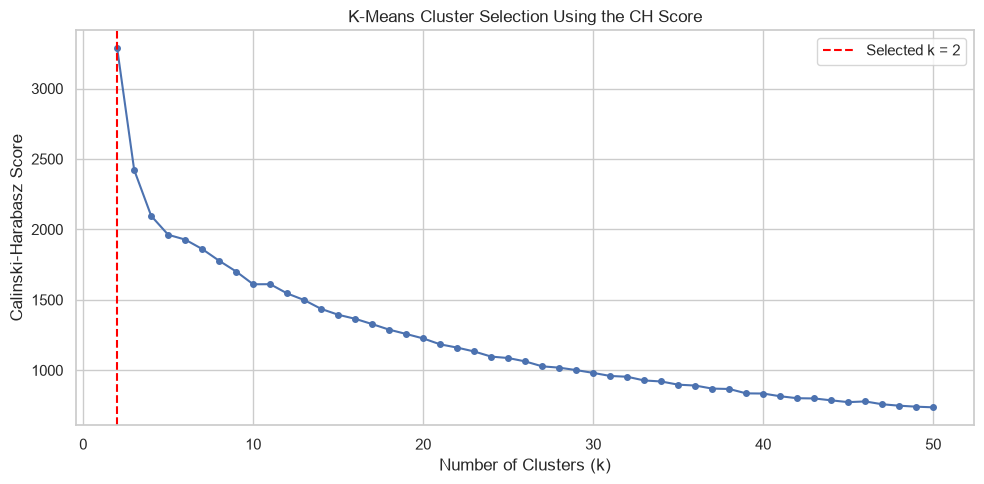

In [8]:
from sklearn.metrics import calinski_harabasz_score

# use all observations and only the 22 mfcc predictors, dont use supervised train/test split for clust
X_cluster = frogs[feature_columns]
cluster_scaler = StandardScaler() # std because k-means deps on euclidean distances
X_cluster_scaled = cluster_scaler.fit_transform(X_cluster)
candidate_k_values = range(2, 51) #requires at least two clusters
ch_scores = []

for k in candidate_k_values:
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    cluster_assignments = kmeans.fit_predict(X_cluster_scaled)
    ch_scores.append(calinski_harabasz_score(X_cluster_scaled, cluster_assignments))

selected_k = list(candidate_k_values)[np.argmax(ch_scores)]
best_ch_score = max(ch_scores)
ch_results = pd.DataFrame({"Number of Clusters": list(candidate_k_values), "CH Score": ch_scores})
print(f"Dataset used for clustering: {X_cluster.shape}")
print("Candidate values: k = 1, 2, ..., 50")
print("Note: k = 1 cannot be evaluated with the Calinski-Harabasz score.")
print(f"Selected number of clusters: {selected_k}")
print(f"Highest CH score: {best_ch_score:.4f}")

plt.figure(figsize=(10, 5))
plt.plot(ch_results["Number of Clusters"], ch_results["CH Score"], marker="o", markersize=4)
plt.axvline(selected_k, color="red", linestyle="--", label=f"Selected k = {selected_k}")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Calinski-Harabasz Score")
plt.title("K-Means Cluster Selection Using the CH Score")
plt.legend()
plt.tight_layout()
plt.show()

#### K-Means Cluster-Number Selection
K-means clustering was applied to all 7,195 observations using the 22 standardized MFCC predictors. The supervised training and testing split wasn't used because this is an unsupervised learning problem. The number of clusters was selected automatically using the Calinski-Harabasz score. Although the assignment considers \(k \in \{1,\ldots,50\}\), the CH score is undefined for \(k=1\), so candidate values from 2 through 50 were evaluated. The maximum CH score was 3284.6059 at \(k=2\). Therefore, two clusters were selected. The CH score decreases as additional clusters are introduced, showing that the strongest separation under this criteria occurs with two clusters.

### (b) Determine which family is the majority

In [9]:
N_REPETITIONS = 50
monte_carlo_runs = []
majority_label_records = []

for iteration in range(1, N_REPETITIONS + 1):
    kmeans = KMeans(n_clusters=selected_k, n_init=10, random_state=RANDOM_STATE + iteration - 1)
    cluster_assignments = kmeans.fit_predict(X_cluster_scaled)
    majority_labels_by_cluster = {}

    for cluster_id in range(selected_k):
        cluster_mask = cluster_assignments == cluster_id
        cluster_true_labels = frogs.loc[cluster_mask, label_columns]
        majority_triplet = {label: cluster_true_labels[label].mode().iloc[0] for label in label_columns}
        majority_labels_by_cluster[cluster_id] = (majority_triplet)
        majority_label_records.append({"Iteration": iteration, "Cluster": cluster_id, "Cluster Size": cluster_mask.sum(), "Majority Family": majority_triplet["Family"], "Majority Genus": majority_triplet["Genus"], "Majority Species": majority_triplet["Species"]})

    monte_carlo_runs.append({"Iteration": iteration, "Cluster Assignments": cluster_assignments, "Majority Labels": majority_labels_by_cluster})

majority_label_results = pd.DataFrame(majority_label_records)
print(f"Completed K-means repetitions: {len(monte_carlo_runs)}")
print(f"Selected number of clusters: {selected_k}")
print(
    "Total cluster-majority triplets calculated: "
    f"{len(majority_label_results)}"
)
print("\nMajority-label triplets from the first five repetitions:")
display(majority_label_results.head(5 * selected_k))

Completed K-means repetitions: 50
Selected number of clusters: 2
Total cluster-majority triplets calculated: 100

Majority-label triplets from the first five repetitions:


,Iteration,Cluster,Cluster Size,Majority Family,Majority Genus,Majority Species
0,1,0,3628,Hylidae,Hypsiboas,HypsiboasCordobae
1,1,1,3567,Leptodactylidae,Adenomera,AdenomeraHylaedactylus
2,2,0,3628,Hylidae,Hypsiboas,HypsiboasCordobae
3,2,1,3567,Leptodactylidae,Adenomera,AdenomeraHylaedactylus
4,3,0,3567,Leptodactylidae,Adenomera,AdenomeraHylaedactylus
5,3,1,3628,Hylidae,Hypsiboas,HypsiboasCordobae
6,4,0,3628,Hylidae,Hypsiboas,HypsiboasCordobae
7,4,1,3567,Leptodactylidae,Adenomera,AdenomeraHylaedactylus
8,5,0,3628,Hylidae,Hypsiboas,HypsiboasCordobae
9,5,1,3567,Leptodactylidae,Adenomera,AdenomeraHylaedactylus


#### Cluster Majority Labels
K-means clustering was repeated 50 times using the automatically selected value \(k=2\). For every repetition, the true labels within each cluster were examined separately, and the modal family, genus, and species were assigned as that cluster's majority-label triplet. A total of 100 cluster-majority triplets were calculated, two clusters for each of the 50 repetitions. The two cluster sizes were consistently 3,628 and 3,567, which accounted for all 7,195 observations.

The two majority-label triplets were consistently:
1. Family: Hylidae; Genus: Hypsiboas; Species: HypsiboasCordobae
2. Family: Leptodactylidae; Genus: Adenomera; Species: AdenomeraHylaedactylus

The numerical cluster identifiers occasionally switched between repetitions. This doesn't represent a change in the clustering because cluster numbers are arbitrary. The cluster compositions and majority-label triplets stayed stable.

### (c) Calculate the average Hamming distance, Hamming score, and Hamming loss

In [10]:
true_label_array = frogs[label_columns].to_numpy()
clustering_metric_records = []

for run in monte_carlo_runs:
    cluster_assignments = run["Cluster Assignments"]
    majority_labels = run["Majority Labels"]
    assigned_label_array = np.empty(shape=true_label_array.shape, dtype=object)

    for cluster_id, majority_triplet in majority_labels.items():
        cluster_mask = cluster_assignments == cluster_id
        assigned_label_array[cluster_mask] = [majority_triplet[label] for label in label_columns]

    label_mismatches = (true_label_array != assigned_label_array)
    average_hamming_distance = (label_mismatches.sum(axis=1).mean()) # avg num of incorrect labels/observation
    run_hamming_loss = label_mismatches.mean() # prop of all individual labels predicted incorrectly
    run_hamming_score = 1 - run_hamming_loss # prop of all individual labels predicted correctly

    clustering_metric_records.append({"Iteration": run["Iteration"], "Average Hamming Distance": (average_hamming_distance), "Hamming Score": run_hamming_score, "Hamming Loss": run_hamming_loss})

clustering_metrics = pd.DataFrame(clustering_metric_records)
clustering_summary = (clustering_metrics[["Average Hamming Distance", "Hamming Score", "Hamming Loss"]].agg(["mean", "std", "min", "max"]).T)
print("Hamming metrics from the first ten repetitions:")
display(clustering_metrics.head(10).style.format({"Average Hamming Distance": "{:.4f}", "Hamming Score": "{:.4f}", "Hamming Loss": "{:.4f}"}))
print("\nSummary across all 50 repetitions:")
display(clustering_summary.style.format("{:.4f}"))
print(
    "\nVerification: mean Hamming distance / 3 = "
    f"{clustering_metrics['Average Hamming Distance'].mean() / 3:.4f}"
)
print(
    "Mean Hamming loss = "
    f"{clustering_metrics['Hamming Loss'].mean():.4f}"
)

Hamming metrics from the first ten repetitions:


,Iteration,Average Hamming Distance,Hamming Score,Hamming Loss
0,1,0.8941,0.7020,0.2980
1,2,0.8941,0.7020,0.2980
2,3,0.8941,0.7020,0.2980
3,4,0.8941,0.7020,0.2980
4,5,0.8941,0.7020,0.2980
5,6,0.8941,0.7020,0.2980
6,7,0.8941,0.7020,0.2980
7,8,0.8941,0.7020,0.2980
8,9,0.8941,0.7020,0.2980
9,10,0.8941,0.7020,0.2980



Summary across all 50 repetitions:


,mean,std,min,max
Average Hamming Distance,0.8941,0.0000,0.8941,0.8941
Hamming Score,0.7020,0.0000,0.7020,0.7020
Hamming Loss,0.2980,0.0000,0.2980,0.2980



Verification: mean Hamming distance / 3 = 0.2980
Mean Hamming loss = 0.2980


#### K-Means Hamming Metrics and Conclusion
For each of the 50 K-means repetitions, every observation was assigned the majority family, genus, and species of its cluster. The assigned triplets were then compared with the true label triplets.
Across all 50 repetitions, the mean results were:
- Average Hamming distance: 0.8941 incorrect labels per observation
- Hamming score: 0.7020
- Hamming loss: 0.2980

Because each observation has three labels, the relationship between the average Hamming distance and Hamming loss is:

$$
\frac{0.8941}{3}=0.2980
$$

So, the cluster-based labels correctly identified approximately 70.20% of the individual family, genus, and species labels and incorrectly identified approximately 29.80%. The standard deviation of each metric was zero across the 50 repetitions. Although the numerical cluster identifiers were switched occasionally, K-means kept finding the same two-cluster partition and the same majority-label triplets. The clustering results are a lot less accurate than the supervised Gaussian SVM results. This is expected because K-means doesn't use the true labels during training and optimizes Euclidean within-cluster similarity rather than classification accuracy.

## 3. ISLR 12.6.2

The pairwise dissimilarities are:

$$
d_{12}=0.30,\quad
d_{13}=0.40,\quad
d_{14}=0.70,\quad
d_{23}=0.50,\quad
d_{24}=0.80,\quad
d_{34}=0.45
$$

### (a) Complete Linkage
The smallest dissimilarity is \(d_{12}=0.30\) so observations 1 and 2 merge first at height 0.30. The complete linkage distances after this merge are:
$$
d(\{1,2\},3)=\max(d_{13},d_{23})
=\max(0.40,0.50)=0.50
$$
$$
d(\{1,2\},4)=\max(d_{14},d_{24})
=\max(0.70,0.80)=0.80
$$
Since \(d_{34}=0.45\), observations 3 and 4 merge at height 0.45 next.
Finally,
$$
d(\{1,2\},\{3,4\})
=
\max(0.40,0.70,0.50,0.80)
=
0.80
$$
So, the complete-linkage fusion sequence is:
1. Observations 1 and 2 merge at height 0.30.
2. Observations 3 and 4 merge at height 0.45.
3. Clusters \(\{1,2\}\) and \(\{3,4\}\) merge at height 0.80.

### (b) Single Linkage
Observations 1 and 2 again merge first at height 0.30. The single linkage distances are:
$$
d(\{1,2\},3)=\min(d_{13},d_{23})
=\min(0.40,0.50)=0.40
$$
$$
d(\{1,2\},4)=\min(d_{14},d_{24})
=\min(0.70,0.80)=0.70
$$
Since the smallest remaining distance is 0.40, observation 3 joins cluster \(\{1,2\}\) at height 0.40. Finally,
$$
d(\{1,2,3\},4)
=
\min(d_{14},d_{24},d_{34})
=
\min(0.70,0.80,0.45)
=
0.45
$$
Therefore, the single linkage fusion sequence is:
1. Observations 1 and 2 merge at height 0.30.
2. Observation 3 joins cluster \(\{1,2\}\) at height 0.40.
3. Observation 4 joins cluster \(\{1,2,3\}\) at height 0.45.

### (c) Complete Linkage Cut to Produce Two Clusters
Cutting the complete linkage dendrogram between heights 0.45 and 0.80 outputs:
$$
\boxed{\{1,2\}\quad\text{and}\quad\{3,4\}}
$$

### (d) Single Linkage Cut to Produce Two Clusters
Cutting the single linkage dendrogram between heights 0.40 and 0.45 outputs:
$$
\boxed{\{1,2,3\}\quad\text{and}\quad\{4\}}
$$

### (e) Equivalent Complete-Linkage Dendrogram
The left and right branches at any fusion can be exchanged without changing the clustering. So, an equivalent complete linkage dendrogram can reverse the leaves to the order \(4,3,2,1\). The fusion heights and cluster memberships stay unchanged.

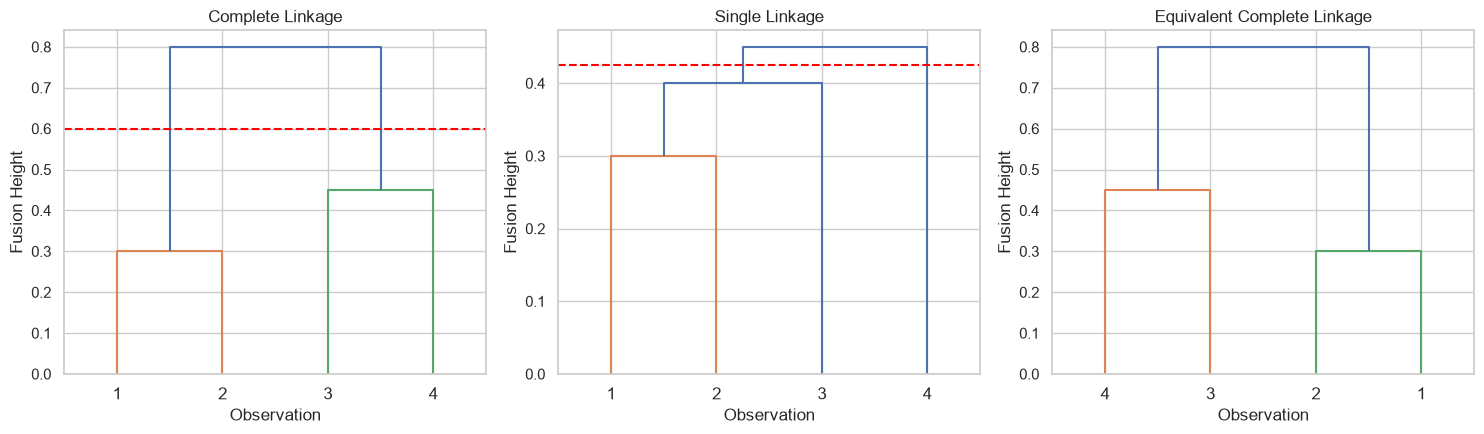

In [11]:
from scipy.cluster.hierarchy import dendrogram

complete_linkage = np.array([[0, 1, 0.30, 2], [2, 3, 0.45, 2], [4, 5, 0.80, 4]]) # link matr. use 0 based observation ids
single_linkage = np.array([[0, 1, 0.30, 2], [4, 2, 0.40, 3], [5, 3, 0.45, 4]])
equivalent_complete_linkage = np.array([[1, 0, 0.30, 2], [3, 2, 0.45, 2], [5, 4, 0.80, 4]]) # same complete linkage fusions w branches reversed

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
dendrogram(complete_linkage, labels=["1", "2", "3", "4"], ax=axes[0])
axes[0].set_title("Complete Linkage")
axes[0].set_xlabel("Observation")
axes[0].set_ylabel("Fusion Height")
axes[0].axhline(0.60, color="red", linestyle="--")

dendrogram(single_linkage, labels=["1", "2", "3", "4"], ax=axes[1])
axes[1].set_title("Single Linkage")
axes[1].set_xlabel("Observation")
axes[1].set_ylabel("Fusion Height")
axes[1].axhline(0.425, color="red", linestyle="--")

dendrogram(equivalent_complete_linkage, labels=["1", "2", "3", "4"], ax=axes[2])
axes[2].set_title("Equivalent Complete Linkage")
axes[2].set_xlabel("Observation")
axes[2].set_ylabel("Fusion Height")

plt.tight_layout()
plt.show()